<a href="https://colab.research.google.com/github/HarshNA044/machine-learning-practice/blob/main/linear_regression/multiple_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Multiple Linear Regression**

It is a statistical and machine learning method used to model and analyze the relationship between one dependent (outcome) variable and two or more independent (predictor) variables. Its primary goal is to find the best-fitting linear equation that predicts the dependent variable using multiple independent variables.

#### **The Equation**

The mathematical formula for multiple linear regression is:

$$
y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \cdots + \beta_n x_n + \epsilon
$$

Where:

- 𝑦
: The dependent variable (the output or target we want to predict).

- 𝑥
1
,
𝑥
2
,
…
,
𝑥
𝑛
: The independent variables (the inputs or features used for prediction).

- 𝛽
0
 (Intercept): The y-intercept, which represents the predicted value of
𝑦
 when all independent variables are equal to zero.

- 𝛽
1
,
𝛽
2
,
…
,
𝛽
𝑛
 (Coefficients): The regression coefficients, which indicate the direction and magnitude of the change in
𝑦
 for every one-unit increase in the corresponding independent variable, while keeping all other variables constant.

- 𝜖
 (Error term / Residual): The random error or noise that accounts for the variation in
𝑦
 that cannot be explained by the linear relationship with the independent variables.


> **Objective:** Predict SalesAmount using multiple independent variables

**Data sourced from [Exploratory-Data-Analysis-EDA--Retail-Sales-Data Repository](https://github.com/tejas79883/Exploratory-Data-Analysis-EDA--Retail-Sales-Data)**

**Direct CSV Link:** https://raw.githubusercontent.com/tejas79883/Exploratory-Data-Analysis-EDA--Retail-Sales-Data/main/Retail.csv

In [1]:
import pandas as pd

# **Step 1: Loading dataset**

In [2]:
# importing dataset
url = "https://raw.githubusercontent.com/tejas79883/Exploratory-Data-Analysis-EDA--Retail-Sales-Data/main/Retail.csv"
data = pd.read_csv(url)

# **Step 2: Understand dataset**

In [3]:
df = pd.DataFrame(data)

In [4]:
df.head()

,OrderNumber,ProductName,Color,Category,Subcategory,ListPrice,Orderdate,Duedate,Shipdate,PromotionName,SalesRegion,OrderQuantity,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight
0,SO43843,"Mountain-100 Silver, 48",Silver,Bikes,Mountain Bikes,3399.9900,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,2039.9940,4079.9880,0.0,326.3990,101.9997
1,SO43843,"Mountain-100 Black, 48",Black,Bikes,Mountain Bikes,3374.9900,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,2024.9940,4049.9880,0.0,323.9990,101.2497
2,SO43843,"HL Mountain Frame - Silver, 46",Silver,Components,Mountain Frames,1204.3248,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,722.5949,1445.1898,0.0,115.6152,36.1297
3,SO43843,"Mountain-100 Black, 44",Black,Bikes,Mountain Bikes,NaN,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,5,2024.9940,10124.9700,0.0,809.9976,253.1243
4,SO43843,"HL Mountain Frame - Silver, 38",Silver,Components,Mountain Frames,1204.3248,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,722.5949,1445.1898,0.0,115.6152,36.1297


In [5]:
df.shape

(32040, 17)

In [6]:
df.columns

Index(['OrderNumber', 'ProductName', 'Color', 'Category', 'Subcategory',
       'ListPrice', 'Orderdate', 'Duedate', 'Shipdate', 'PromotionName',
       'SalesRegion', 'OrderQuantity', 'UnitPrice', 'SalesAmount',
       'DiscountAmount', 'TaxAmount', 'Freight'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32040 entries, 0 to 32039
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   OrderNumber     32040 non-null  object 
 1   ProductName     32040 non-null  object 
 2   Color           29073 non-null  object 
 3   Category        32040 non-null  object 
 4   Subcategory     32040 non-null  object 
 5   ListPrice       32032 non-null  float64
 6   Orderdate       32040 non-null  object 
 7   Duedate         32040 non-null  object 
 8   Shipdate        32040 non-null  object 
 9   PromotionName   32040 non-null  object 
 10  SalesRegion     32025 non-null  object 
 11  OrderQuantity   32026 non-null  object 
 12  UnitPrice       32040 non-null  float64
 13  SalesAmount     32040 non-null  float64
 14  DiscountAmount  32040 non-null  float64
 15  TaxAmount       32040 non-null  float64
 16  Freight         32040 non-null  float64
dtypes: float64(6), object(11)
memor

In [8]:
df.describe(include='all')

,OrderNumber,ProductName,Color,Category,Subcategory,ListPrice,Orderdate,Duedate,Shipdate,PromotionName,SalesRegion,OrderQuantity,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight
count,32040,32040,29073,32040,32040,32032.000000,32040,32040,32040,32040,32025,32026,32040.000000,32040.000000,32040.00000,32040.000000,32040.000000
unique,1871,250,8,4,33,NaN,17,17,17,7,10,38,NaN,NaN,NaN,NaN,NaN
top,SO51739,AWC Logo Cap,Black,Bikes,Road Bikes,NaN,2/28/2013,03-12-2013,03-07-2013,No Discount,Southwest,1,NaN,NaN,NaN,NaN,NaN
freq,72,622,10621,12254,6156,NaN,3760,3760,3760,30275,7010,7356,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,714.663419,NaN,NaN,NaN,NaN,NaN,NaN,424.122103,1299.023131,8.15285,103.921849,32.475594
std,NaN,NaN,NaN,NaN,NaN,851.623778,NaN,NaN,NaN,NaN,NaN,NaN,506.799303,2153.316625,78.40708,172.265331,53.832916
min,NaN,NaN,NaN,NaN,NaN,2.290000,NaN,NaN,NaN,NaN,NaN,NaN,1.328200,1.374000,0.00000,0.109900,0.034400
25%,NaN,NaN,NaN,NaN,NaN,54.990000,NaN,NaN,NaN,NaN,NaN,NaN,32.994000,125.964000,0.00000,10.077100,3.149100
50%,NaN,NaN,NaN,NaN,NaN,337.220000,NaN,NaN,NaN,NaN,NaN,NaN,202.332000,445.410000,0.00000,35.632800,11.135300
75%,NaN,NaN,NaN,NaN,NaN,1079.990000,NaN,NaN,NaN,NaN,NaN,NaN,647.994000,1457.820000,0.00000,116.625600,36.445500


# **Step 3: Data cleaning**

## Copying dataframe

In [9]:
# create a copy to preserve the original dataset
df_cleaned = df.copy()
df_cleaned.head()

,OrderNumber,ProductName,Color,Category,Subcategory,ListPrice,Orderdate,Duedate,Shipdate,PromotionName,SalesRegion,OrderQuantity,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight
0,SO43843,"Mountain-100 Silver, 48",Silver,Bikes,Mountain Bikes,3399.9900,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,2039.9940,4079.9880,0.0,326.3990,101.9997
1,SO43843,"Mountain-100 Black, 48",Black,Bikes,Mountain Bikes,3374.9900,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,2024.9940,4049.9880,0.0,323.9990,101.2497
2,SO43843,"HL Mountain Frame - Silver, 46",Silver,Components,Mountain Frames,1204.3248,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,722.5949,1445.1898,0.0,115.6152,36.1297
3,SO43843,"Mountain-100 Black, 44",Black,Bikes,Mountain Bikes,NaN,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,5,2024.9940,10124.9700,0.0,809.9976,253.1243
4,SO43843,"HL Mountain Frame - Silver, 38",Silver,Components,Mountain Frames,1204.3248,1/29/2011,02-10-2011,02-05-2011,No Discount,Central,2,722.5949,1445.1898,0.0,115.6152,36.1297


## Removing duplicate rows

In [10]:
# Check which rows are duplicated
df_cleaned.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
32035,False
32036,False
32037,False
32038,False


In [11]:
# Count duplicate rows
df_cleaned.duplicated().sum()

np.int64(0)

In [12]:
# Remove duplicates if present
df_cleaned = df_cleaned.drop_duplicates()

## Checking missing values

In [13]:
df_cleaned.count()

,0
OrderNumber,32040
ProductName,32040
Color,29073
Category,32040
Subcategory,32040
ListPrice,32032
Orderdate,32040
Duedate,32040
Shipdate,32040
PromotionName,32040


In [14]:
# Check total missing values in each column
df_cleaned.isnull().sum()

,0
OrderNumber,0
ProductName,0
Color,2967
Category,0
Subcategory,0
ListPrice,8
Orderdate,0
Duedate,0
Shipdate,0
PromotionName,0


In [15]:
# Check unique values in categorical column
text_columns = df_cleaned.select_dtypes(include='object').columns

for col in text_columns:
    print("Column Name:", col)
    print("Unique Labels:", df_cleaned[col].unique(), "\n")

Column Name: OrderNumber
Unique Labels: ['SO43843' 'SO43844' 'SO43845' ... 'SO61266' 'SO61267' 'SO61268'] 

Column Name: ProductName
Unique Labels: ['Mountain-100 Silver, 48' 'Mountain-100 Black, 48'
 'HL Mountain Frame - Silver, 46' 'Mountain-100 Black, 44'
 'HL Mountain Frame - Silver, 38' 'HL Mountain Frame - Silver, 48'
 'HL Mountain Frame - Black, 48' 'Mountain-100 Silver, 38'
 'Mountain Bike Socks, M' 'Mountain-100 Black, 42'
 'Mountain-100 Black, 38' 'LL Road Frame - Red, 44'
 'Long-Sleeve Logo Jersey, L' 'Road-650 Black, 52' 'Road-650 Red, 48'
 'Road-650 Red, 62' 'Road-450 Red, 58' 'Road-650 Black, 58'
 'Road-150 Red, 56' 'LL Road Frame - Red, 60' 'AWC Logo Cap'
 'LL Road Frame - Black, 52' 'Road-450 Red, 52' 'Mountain-100 Silver, 44'
 'Long-Sleeve Logo Jersey, M' 'Sport-100 Helmet, Blue'
 'Mountain-100 Silver, 42' 'Sport-100 Helmet, Red'
 'Sport-100 Helmet, Black' 'Road-450 Red, 60' 'Road-650 Red, 44'
 'Road-450 Red, 44' 'ML Road Frame - Red, 48' 'Road-650 Red, 60'
 'Road-650 

## Fixing inconsistent formats

In [16]:
# changing date features from object to datetime
df_cleaned['Orderdate'] = pd.to_datetime(
    df_cleaned['Orderdate'],
    format='mixed'
)

In [17]:
df_cleaned['Shipdate'] = pd.to_datetime(
    df_cleaned['Shipdate'],
    format='mixed'
)

In [18]:
df_cleaned['Duedate'] = pd.to_datetime(
    df_cleaned['Duedate'],
    format='mixed'
)

In [19]:
# change OrderQuantity datatype from object to numeric
df_cleaned['OrderQuantity'] = pd.to_numeric(
    df_cleaned['OrderQuantity'],
    errors='coerce'
)

## Checking impossible values

In [20]:
df_cleaned.describe()

,ListPrice,Orderdate,Duedate,Shipdate,OrderQuantity,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight
count,32032.000000,32040,32040,32040,32024.000000,32040.000000,32040.000000,32040.00000,32040.000000,32040.000000
mean,714.663419,2012-08-26 13:08:48.539325696,2012-09-07 13:08:48.539325696,2012-09-02 13:08:48.539325952,3.626468,424.122103,1299.023131,8.15285,103.921849,32.475594
min,2.290000,2011-01-29 00:00:00,2011-02-10 00:00:00,2011-02-05 00:00:00,1.000000,1.328200,1.374000,0.00000,0.109900,0.034400
25%,54.990000,2012-02-29 00:00:00,2012-03-12 00:00:00,2012-03-07 00:00:00,2.000000,32.994000,125.964000,0.00000,10.077100,3.149100
50%,337.220000,2013-01-28 00:00:00,2013-02-09 00:00:00,2013-02-04 00:00:00,3.000000,202.332000,445.410000,0.00000,35.632800,11.135300
75%,1079.990000,2013-03-30 00:00:00,2013-04-11 00:00:00,2013-04-06 00:00:00,5.000000,647.994000,1457.820000,0.00000,116.625600,36.445500
max,3578.270000,2013-06-30 00:00:00,2013-07-12 00:00:00,2013-07-07 00:00:00,40.000000,2146.962000,27893.619000,4005.23760,2231.489500,697.340500
std,851.623778,NaN,NaN,NaN,3.116480,506.799303,2153.316625,78.40708,172.265331,53.832916


In [21]:
# Check whether ListPrice contains zero or negative values
df_cleaned[df_cleaned['ListPrice'] <= 0]

,OrderNumber,ProductName,Color,Category,Subcategory,ListPrice,Orderdate,Duedate,Shipdate,PromotionName,SalesRegion,OrderQuantity,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight


In [22]:
# Check negative SalesAmount values
df_cleaned[df_cleaned['SalesAmount'] < 0]

,OrderNumber,ProductName,Color,Category,Subcategory,ListPrice,Orderdate,Duedate,Shipdate,PromotionName,SalesRegion,OrderQuantity,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight


In [23]:
# Check negative DiscountAmount values
df_cleaned[df_cleaned['DiscountAmount'] < 0]

,OrderNumber,ProductName,Color,Category,Subcategory,ListPrice,Orderdate,Duedate,Shipdate,PromotionName,SalesRegion,OrderQuantity,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight


## Remove records where target variable is missing

In [24]:
df_cleaned = df_cleaned.dropna(subset=['SalesAmount'])

## Analysing cleaned data

In [25]:
df_cleaned.shape

(32040, 17)

In [26]:
df_cleaned.head()

,OrderNumber,ProductName,Color,Category,Subcategory,ListPrice,Orderdate,Duedate,Shipdate,PromotionName,SalesRegion,OrderQuantity,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight
0,SO43843,"Mountain-100 Silver, 48",Silver,Bikes,Mountain Bikes,3399.9900,2011-01-29,2011-02-10,2011-02-05,No Discount,Central,2.0,2039.9940,4079.9880,0.0,326.3990,101.9997
1,SO43843,"Mountain-100 Black, 48",Black,Bikes,Mountain Bikes,3374.9900,2011-01-29,2011-02-10,2011-02-05,No Discount,Central,2.0,2024.9940,4049.9880,0.0,323.9990,101.2497
2,SO43843,"HL Mountain Frame - Silver, 46",Silver,Components,Mountain Frames,1204.3248,2011-01-29,2011-02-10,2011-02-05,No Discount,Central,2.0,722.5949,1445.1898,0.0,115.6152,36.1297
3,SO43843,"Mountain-100 Black, 44",Black,Bikes,Mountain Bikes,NaN,2011-01-29,2011-02-10,2011-02-05,No Discount,Central,5.0,2024.9940,10124.9700,0.0,809.9976,253.1243
4,SO43843,"HL Mountain Frame - Silver, 38",Silver,Components,Mountain Frames,1204.3248,2011-01-29,2011-02-10,2011-02-05,No Discount,Central,2.0,722.5949,1445.1898,0.0,115.6152,36.1297


In [27]:
# save the clean dataset
df_cleaned.to_csv('cleaned_dataset.csv', index=False)

# **Step 4: Data Preprocessing**

In [28]:
df_cleaned.isnull().sum()

,0
OrderNumber,0
ProductName,0
Color,2967
Category,0
Subcategory,0
ListPrice,8
Orderdate,0
Duedate,0
Shipdate,0
PromotionName,0


In [29]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32040 entries, 0 to 32039
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   OrderNumber     32040 non-null  object        
 1   ProductName     32040 non-null  object        
 2   Color           29073 non-null  object        
 3   Category        32040 non-null  object        
 4   Subcategory     32040 non-null  object        
 5   ListPrice       32032 non-null  float64       
 6   Orderdate       32040 non-null  datetime64[ns]
 7   Duedate         32040 non-null  datetime64[ns]
 8   Shipdate        32040 non-null  datetime64[ns]
 9   PromotionName   32040 non-null  object        
 10  SalesRegion     32025 non-null  object        
 11  OrderQuantity   32024 non-null  float64       
 12  UnitPrice       32040 non-null  float64       
 13  SalesAmount     32040 non-null  float64       
 14  DiscountAmount  32040 non-null  float64       
 15  Ta

## Handling missing values

In [30]:
# filling null values for Color feature with mode as its null values count (2967) is approx 9% of the dataset
df_cleaned['Color'] = df_cleaned['Color'].fillna(df_cleaned['Color'].mode()[0])

In [31]:
# dropping null values for ListPrice, OrderQuantity and SalesRegion
df_cleaned = df_cleaned.dropna(subset=['ListPrice', 'OrderQuantity', 'SalesRegion'])

In [32]:
df_cleaned.isnull().sum()

,0
OrderNumber,0
ProductName,0
Color,0
Category,0
Subcategory,0
ListPrice,0
Orderdate,0
Duedate,0
Shipdate,0
PromotionName,0


## Extract information from OrderDate

In [33]:
df_cleaned['Order_Year'] = df_cleaned['Orderdate'].dt.year

df_cleaned['Order_Month'] = df_cleaned['Orderdate'].dt.month

df_cleaned['Order_Day'] = df_cleaned['Orderdate'].dt.day

# **Step 5: Exploratory data analysis (EDA)**

In [34]:
# describe: provide statistical summary
df_cleaned.describe()

,ListPrice,Orderdate,Duedate,Shipdate,OrderQuantity,UnitPrice,SalesAmount,DiscountAmount,TaxAmount,Freight,Order_Year,Order_Month,Order_Day
count,32001.000000,32001,32001,32001,32001.000000,32001.000000,32001.000000,32001.000000,32001.000000,32001.000000,32001.000000,32001.000000,32001.000000
mean,714.163330,2012-08-26 18:54:24.872972800,2012-09-07 18:54:24.872972544,2012-09-02 18:54:24.872972800,3.626605,423.807271,1298.586374,8.037626,103.886908,32.464676,2012.401800,3.147902,27.847817
min,2.290000,2011-01-29 00:00:00,2011-02-10 00:00:00,2011-02-05 00:00:00,1.000000,1.328200,1.374000,0.000000,0.109900,0.034400,2011.000000,1.000000,1.000000
25%,54.990000,2012-02-29 00:00:00,2012-03-12 00:00:00,2012-03-07 00:00:00,2.000000,32.994000,125.964000,0.000000,10.077100,3.149100,2012.000000,2.000000,28.000000
50%,337.220000,2013-01-28 00:00:00,2013-02-09 00:00:00,2013-02-04 00:00:00,3.000000,202.332000,445.410000,0.000000,35.632800,11.135300,2013.000000,3.000000,30.000000
75%,1079.990000,2013-03-30 00:00:00,2013-04-11 00:00:00,2013-04-06 00:00:00,5.000000,647.994000,1457.820000,0.000000,116.625600,36.445500,2013.000000,5.000000,30.000000
max,3578.270000,2013-06-30 00:00:00,2013-07-12 00:00:00,2013-07-07 00:00:00,40.000000,2146.962000,27893.619000,3099.291000,2231.489500,697.340500,2013.000000,6.000000,31.000000
std,850.931322,NaN,NaN,NaN,3.115602,506.327556,2151.708191,75.205046,172.136656,53.792705,0.689965,1.660807,6.415408


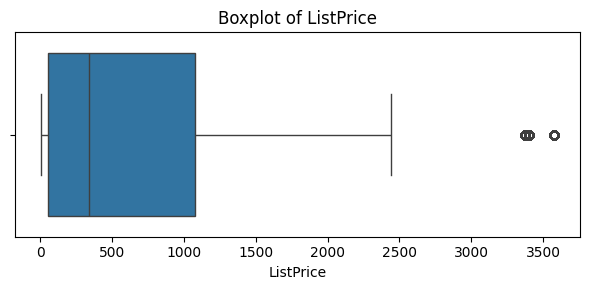

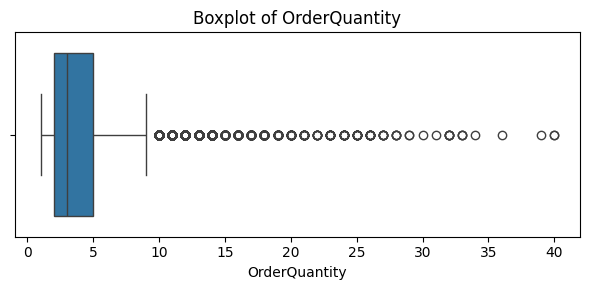

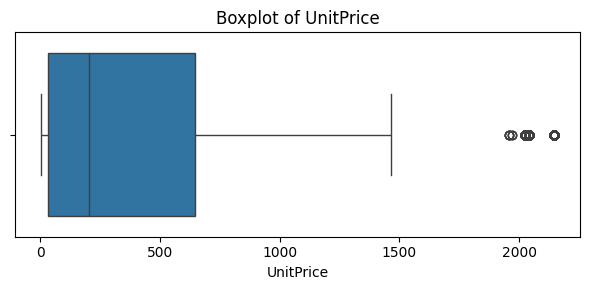

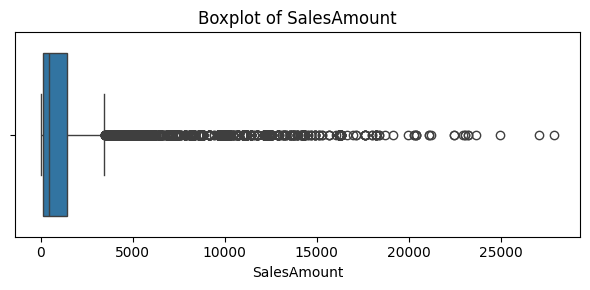

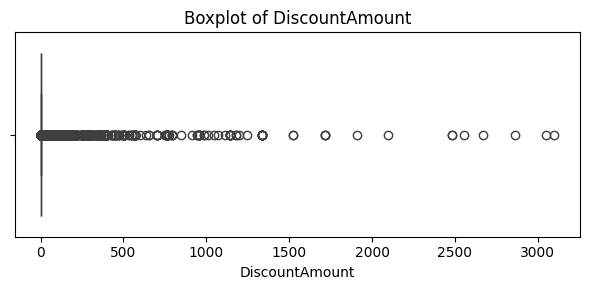

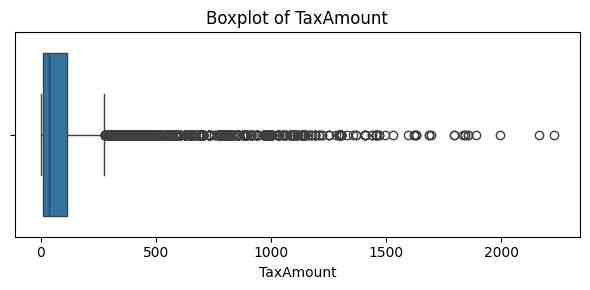

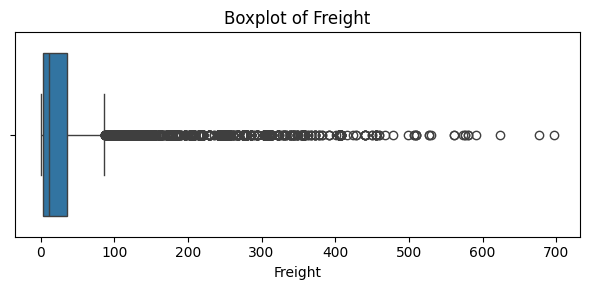

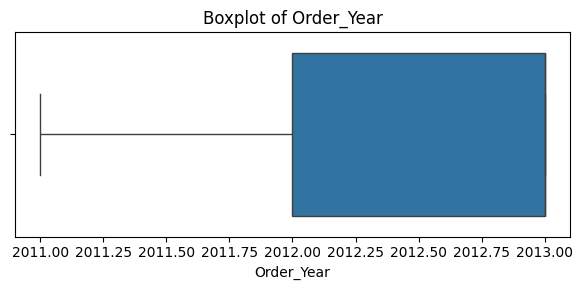

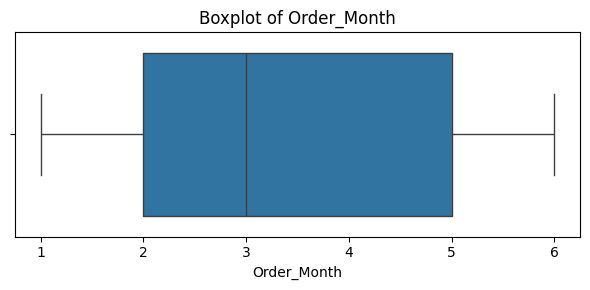

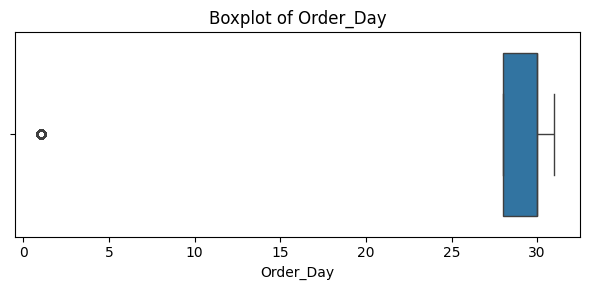

In [35]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = df_cleaned.select_dtypes(include=np.number).columns

for col in numerical_columns:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df_cleaned[col])
    plt.title(f'Boxplot of {col}')
    plt.tight_layout()

    plt.show()

## Identify outlier using IQR

In [36]:
Q1 = df_cleaned[numerical_columns].quantile(0.25)
Q3 = df_cleaned[numerical_columns].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers_count = (
    (df_cleaned[numerical_columns] < lower_limit) |
    (df_cleaned[numerical_columns] > upper_limit)
).sum()

print(outliers_count)

ListPrice          839
OrderQuantity     1606
UnitPrice          839
SalesAmount       3372
DiscountAmount    1764
TaxAmount         3372
Freight           3372
Order_Year           0
Order_Month          0
Order_Day         1698
dtype: int64


**Capping (or Winsorization)** is an outlier handling technique that replaces extreme values with maximum and minimum thresholds instead of deleting them.
Instead of removing data points, you set a boundary:

- Any value above the upper limit is changed to match the upper limit.
- Any value below the lower limit is changed to match the lower limit.

In [37]:
for col in numerical_columns:

    df_cleaned[col] = df_cleaned[col].clip(
        lower=lower_limit[col],
        upper=upper_limit[col]
    )

In [38]:
outliers_after = (
    (df_cleaned[numerical_columns] < lower_limit) |
    (df_cleaned[numerical_columns] > upper_limit)
).sum()

print("Outliers after capping:")
print(outliers_after)

Outliers after capping:
ListPrice         0
OrderQuantity     0
UnitPrice         0
SalesAmount       0
DiscountAmount    0
TaxAmount         0
Freight           0
Order_Year        0
Order_Month       0
Order_Day         0
dtype: int64


# **Step 6: Feature Selection Using Correlation Matrix**

Our target variable is SalesAmount

In [39]:
# visualize correlation matrix for numerical features
correlation = df_cleaned.select_dtypes(
    include=np.number
).corr()

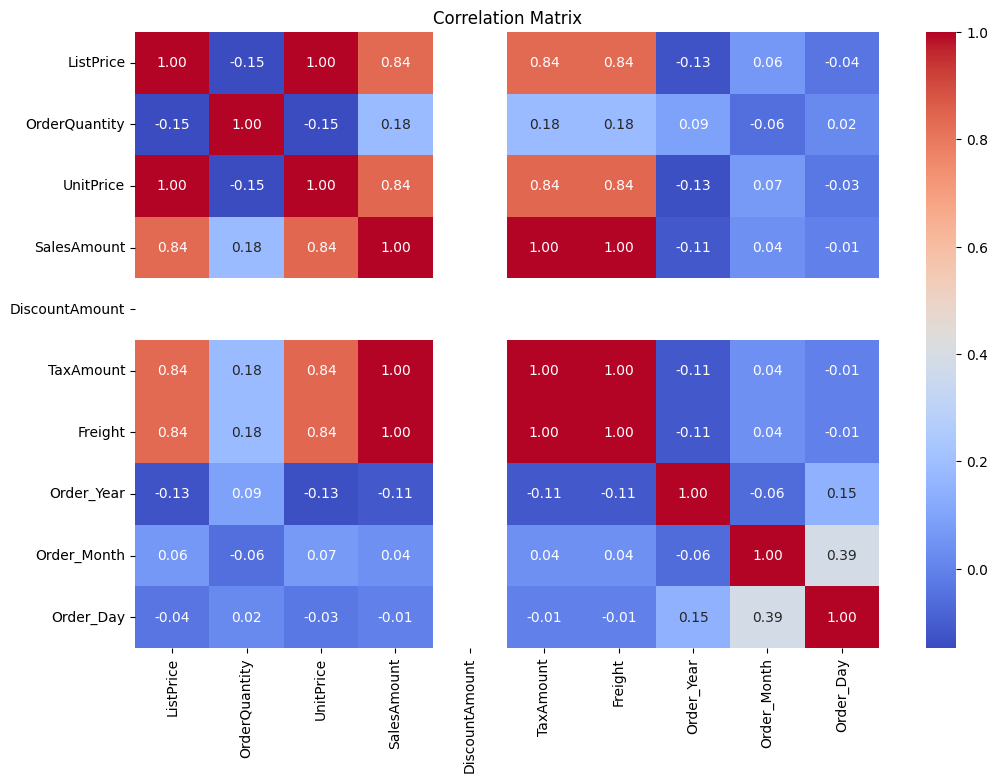

In [40]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Matrix")

plt.show()

In [41]:
target_correlation = correlation['SalesAmount'].sort_values(
    ascending=False
)

print(target_correlation)

SalesAmount       1.000000
TaxAmount         1.000000
Freight           1.000000
UnitPrice         0.841831
ListPrice         0.838565
OrderQuantity     0.182400
Order_Month       0.039083
Order_Day        -0.007760
Order_Year       -0.113179
DiscountAmount         NaN
Name: SalesAmount, dtype: float64


### Features to Keep (Independent Variables)

1. **UnitPrice (0.8418):** Strong positive correlation with SalesAmount, making it an important predictor.

2. **OrderQuantity (0.1820):** Weak positive correlation, but may provide additional predictive information. We retain it initially to build a Multiple Linear Regression model with two independent variables and evaluate its usefulness.

### Features to Remove

| Feature | Correlation | Reason |
|---|---:|---|
| ListPrice | 0.8386 | Highly correlated with UnitPrice (1.00), providing redundant information. |
| TaxAmount | 1.0000 | Perfect correlation with target; possible target leakage. |
| Freight | 1.0000 | Perfect correlation with target; possible target leakage. |
| Order_Year | -0.1131 | Very weak negative correlation. |
| Order_Month | 0.0391 | Very weak positive correlation. |
| Order_Day | -0.0078 | Almost no correlation. |
| DiscountAmount | NaN | Correlation cannot be calculated; requires further investigation. |

### Final Feature Selection

- **Independent Variables (X):** UnitPrice, OrderQuantity
- **Dependent Variable (y):** SalesAmount

**Conclusion:** UnitPrice is selected because of its strong positive correlation with SalesAmount. OrderQuantity is retained because it may provide additional predictive information. Its contribution will be evaluated using model performance.

In [42]:
# Independent variable
X = df_cleaned[['UnitPrice','OrderQuantity']] # Double square brackets keep X in DataFrame format.

# Dependent variable
y = df_cleaned['SalesAmount']

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (32001, 2)
y Shape: (32001,)


In [43]:
X

,UnitPrice,OrderQuantity
0,1570.4940,2.0
1,1570.4940,2.0
2,722.5949,2.0
4,722.5949,2.0
5,818.7000,1.0
...,...,...
32035,1430.4420,2.0
32036,728.9100,1.0
32037,602.3460,2.0
32038,728.9100,2.0


In [44]:
y

,SalesAmount
0,3455.6040
1,3455.6040
2,1445.1898
4,1445.1898
5,818.7000
...,...
32035,2860.8840
32036,728.9100
32037,1204.6920
32038,1457.8200


# **Step 7: Data splitting (Train-test split)**
> It is a critical data preparation technique used in machine learning to divide a single dataset into two separate, non-overlapping subsets. This ensures that the model can be evaluated fairly on data it has never seen before, preventing it from simply memorizing the answers (overfitting).

#### **The Two Main Subsets**
*   **Training Set:** The larger portion of the dataset (typically **70% to 80%**) used by the machine learning algorithm to learn patterns, fit the regression line, and optimize its parameters.
*   **Testing Set:** The remaining portion of the data (typically **20% to 30%**) held back and kept completely hidden from the model during training. It acts as an unbiased benchmark to test the model's accuracy.

#### **Why Splitting is Essential**
1. **Evaluates Generalization:** It proves whether the model can accurately make predictions on real-world, unseen data.
2. **Detects Overfitting:** If a model scores perfectly on the training data but performs poorly on the test data, it has overfit the data.
3. **Ensures Objectivity:** Evaluating a model on the same data it learned from produces a falsely optimistic performance score.



In [45]:
# importing train test-test split function
from sklearn.model_selection import train_test_split
''' sklearn: scikit learn library
    model_selection: module
    train_test_split: function
'''

' sklearn: scikit learn library\n    model_selection: module\n    train_test_split: function\n'

In [46]:
# split the data into training and testing  parts
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

`X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)`

**What each part means:**

*   **`X, y`**: The original inputs (`X`) and targets (`y`) that we separated during feature-label separation.
*   **`test_size=0.2`**: Saves **20%** of your data for testing and uses the remaining **80%** for training.
*   **`random_state=42`**: Acts like a **"lock" for randomness**. It ensures your data is shuffled and split the exact same way every single time you run the code, making your results reproducible.
*   **`X_train, X_test, y_train, y_test`**: The four separate sets created by the function. They must be written in this **exact order** (Features first, then Labels).


In [47]:
df_cleaned.shape

(32001, 20)

In [48]:
X_train.shape

(25600, 2)

In [49]:
X_test.shape

(6401, 2)

In [50]:
y_train.shape

(25600,)

In [51]:
y_test.shape

(6401,)

# **Step 8: Creating & Training Multiple linear regression model**

In [52]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [53]:
# train the model
model.fit(X_train, y_train)

LinearRegression()

In [54]:
# checking intercept and slope
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: -410.10889483831807
Coefficients: [  2.16194883 150.05650966]


The regression equation will be:

SalesAmount=β
0
	​
+β
1
	​
*(UnitPrice)

Where:

β₀ = Intercept

β₁ = UnitPrice coefficient

# **Step 9: Making predictions using testing data**

In [55]:
y_pred = model.predict(X_test)
y_pred

array([1343.46935407, 1073.06133659,  796.3945473 , ...,  848.00894879,
        -39.96170498,  512.34700479], shape=(6401,))

In [56]:
y_pred[:10]

array([1343.46935407, 1073.06133659,  796.3945473 , 1066.19915337,
       1349.02711096,  -47.64440635, 1042.18884735,  587.50488898,
        525.40939456,  347.67132706])

# **Step 10: Model Evaluation Metrics**

## Mean Squared Error (MSE)

MSE represents the average squared difference between the actual target variable and our predicted target variable

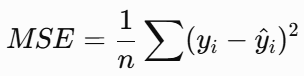

In [57]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, y_pred)
mse

252186.7203317011

## R-squared Score (R²)

R² score (Coefficient of determination) measures the proportion of variance in the dependent variable that can be predicted by our independent variable

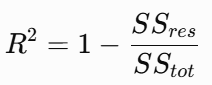

- Closer to 1: The model fits the data exceptionally well.

- Closer to 0 or negative: The model is a poor fit and does not predict the target effectively.

In [58]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)
r2

0.803569735058685

# **Step 11: Comparing actual and predicted values**

In [59]:
comparison = pd.DataFrame({
    'Actual SalesAmount': y_test.values,
    'Predicted SalesAmount': y_pred
})

comparison.head(10)

,Actual SalesAmount,Predicted SalesAmount
0,1344.5880,1343.469354
1,1694.9700,1073.061337
2,849.6900,796.394547
3,234.8400,1066.199153
4,744.2727,1349.027111
5,57.6808,-47.644406
6,602.3460,1042.188847
7,269.9640,587.504889
8,97.6320,525.409395
9,291.5040,347.671327


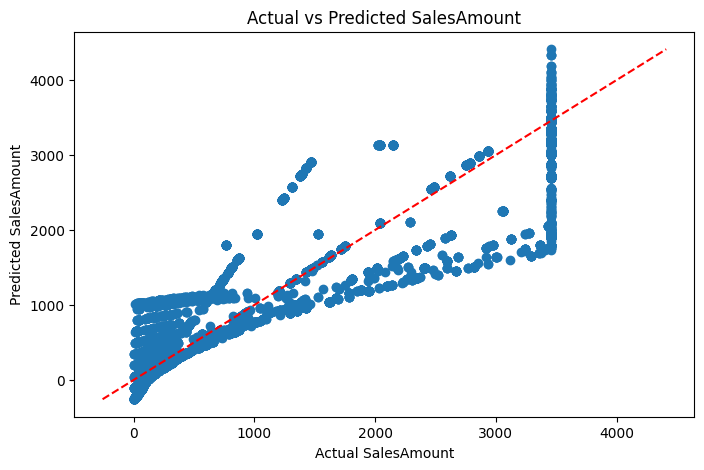

In [60]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual SalesAmount")

plt.ylabel("Predicted SalesAmount")

plt.title("Actual vs Predicted SalesAmount")

min_value = min(y_test.min(), y_pred.min())

max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color='red',
    linestyle='--'
)

plt.show()

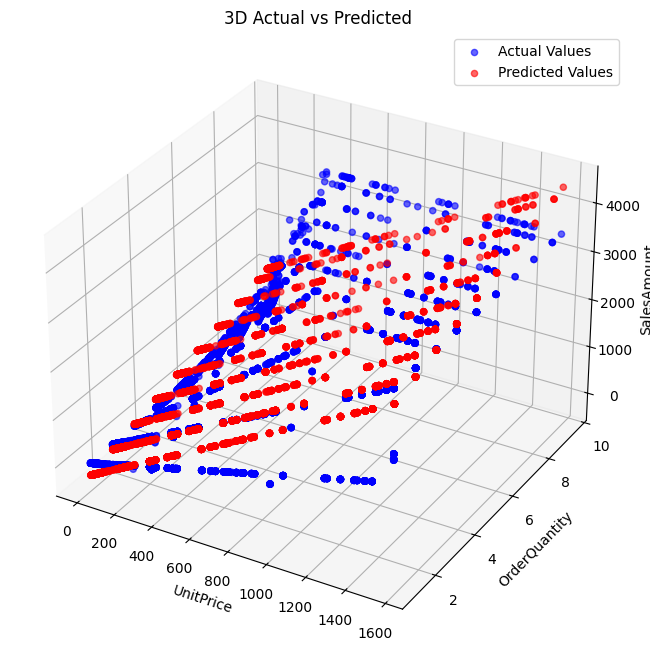

In [61]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot all actual values
ax.scatter(X_test['UnitPrice'], X_test['OrderQuantity'], y_test, color='blue', alpha=0.6, label='Actual Values')

# Plot all predicted values
ax.scatter(X_test['UnitPrice'], X_test['OrderQuantity'], y_pred,color='red', alpha=0.6, label='Predicted Values')

# Axis labels
ax.set_xlabel('UnitPrice')
ax.set_ylabel('OrderQuantity')
ax.set_zlabel('SalesAmount')
ax.set_title('3D Actual vs Predicted')
ax.legend()
plt.show()

## K-Fold Cross-Validation

It is a robust model evaluation technique. Instead of
testing machine learning model just once on an arbitrary chunk of data,
it shuffles and splits dataset into 'K' equal parts (folds).

The model loops K times. In each loop, a different fold acts as the testing data (validation set) while the remaining folds are used for training. Finally, it
averages the scores from all K loops. This guarantees every single row of dataset gets tested, preventing misleading results.

We use training data for K-Fold Cross Validation because we want to evaluate how consistently the model performs during training without touching the testing data.

If we use X and y, we include the testing data in cross-validation.
This means the model-development process gets information from data that should remain untouched for final evaluation.

In [62]:
from sklearn.model_selection import KFold, cross_val_score

# K=5 folds is standard
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2')

print("Cross Validation Scores:", cv_scores)
print("Average R² Score:", cv_scores.mean())

Cross Validation Scores: [0.80682782 0.81003024 0.80286212 0.79965602 0.8057218 ]
Average R² Score: 0.8050195987280372


# **Step 12: Predicting SaleAmount for new values**

In [63]:
new_data = pd.DataFrame({
    'UnitPrice': [2500],
    'OrderQuantity': [1] # Added missing feature
})

new_prediction = model.predict(new_data)
new_prediction

array([5144.81970048])

# **Step 13: Conclusion**
Multiple Linear Regression model achieved a Mean Squared Error (MSE) of 252,186.72 and an $R^2$ score of 0.8036 (80.36%), indicating that the model successfully explains approximately 80.36% of the variation in SalesAmount using two features: UnitPrice and OrderQuantity.

The 5-fold cross-validation scores were highly consistent across all folds (ranging between 79.97% and 81.00%) with an average cross-validation $R^2$ score of 0.8050 (80.50%). This high level of consistency confirms that our multiple linear regression model is highly robust, generalizes exceptionally well, and is not overfitted to any specific subset of data.

### **Overall Comparison with Simple Linear Regression**
By upgrading from Simple Linear Regression (using only ListPrice) to Multiple Linear Regression (using both UnitPrice and OrderQuantity), we achieved a massive leap in predictive accuracy:

The $R^2$ score improved from 59.61% for simple linear regression model to 80.36% for multiple linear regression model.
The average cross-validation score increased from 59.00% to 80.50%.
The MSE decreased from 253,405.20 to 252,186.72, meaning average prediction errors are lower.

### **Conclusion:**
Adding OrderQuantity alongside UnitPrice drastically improved the model's performance from moderate to strong, establishing a highly reliable and powerful model for predicting sales outcomes.